# deepagents vs LangGraph: when does the harness pay off?
Same model, tools and data for both agents. See `README.md` for the design, results and findings.

## 1. Setup
Install, versions, API key, model (`gemini-3.8-flash`, temperature 0).

In [ ]:
!pip install -q -U langgraph deepagents langchain-google-genai

In [ ]:
import langgraph, deepagents, langchain_google_genai
from importlib.metadata import version
print("Langgraph:",version("langgraph"), "\ndeepagents:",version("deepagents"), "\nlangchain-google-genai:",version("langchain-google-genai"))

Langgraph: 1.2.20 
deepagents: 0.7.34 
langchain-google-genai: 4.4.3


In [ ]:
import os
from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()

secret_value = secrets.get_secret("GOOGLE_API_KEY")

os.environ["GOOGLE_API_KEY"] = secret_value

print(len(secret_value))

53


In [ ]:
from google import genai

client = genai.Client()

for model in client.models.list():
    if "flash" in model.name:
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash


In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

MODEL_NAME = "gemini-3.8-flash"

llm = ChatGoogleGenerativeAI(model = MODEL_NAME, temperature = 0, max_retries=3)

## 2. Test bench
Synthetic pricing reports for a fictional drug plus `answer_key.json` (answers computed by code); then the medium (approx. 17k tokens/report) and large (approx. 28k tokens/report) stress tiers built from the same facts.

In [ ]:
import json
r2=lambda x: round(x+1e-9,2)
FX={"EUR":1.0,"GBP":1.17,"SEK":0.087}
C={
"germany":dict(name="Germany",cur="EUR",vat=0.19,ptw=(1200,1020),pth=(1080,950),
  w="Wholesaler margin (PTW -> PTC): 3.15% of PTW, capped at 37.80 per pack.",
  p="Pharmacy margin (PTC -> PTP): 3% of PTC plus a fixed fee of 8.35 per pack.",
  noise=["The benefit assessment rated Xelora 'minor added benefit' versus the comparator; the month-12 PTW reflects the negotiated price.",
         "Competitor Branvit launched in Q3 2025 at PTW 1,150.00 (pack of 30). Branvit is not relevant to Xelora pricing.",
         "A 90-tablet pack of Xelora is listed at PTW 3,450.00 but is not reimbursed and is excluded from this report's analysis."]),
"france":dict(name="France",cur="EUR",vat=0.021,ptw=(980,905),pth=(900,840),
  w="Wholesaler margin (PTW -> PTC): 6.68% of PTW if PTW is 450.00 or below; if PTW is above 450.00, a fixed 30.00 per pack.",
  p="Pharmacy margin (PTC -> PTP): 10% of PTC, capped at 96.00, plus a dispensing fee of 1.02 per pack.",
  noise=["The HAS rated Xelora ASMR IV (minor improvement). Price was set by the CEPS with a 2-step price cut schedule.",
         "Confidential rebates exist but are not reflected in any list price in this report.",
         "Hospital use accounts for roughly 35% of volume."]),
"italy":dict(name="Italy",cur="EUR",vat=0.10,ptw=(1050,960),pth=(990,900),
  w="Margins are defined as a share of PTP (ex-VAT): the manufacturer receives 66.65% of PTP (this is PTW), the wholesaler receives 3.00% of PTP, the pharmacy receives 30.35% of PTP.",
  p="Therefore PTP = PTW / 0.6665 and PTC = PTW + 3.00% of PTP.",
  noise=["AIFA classified Xelora in class A (reimbursed). A mandatory 5% temporary reduction applied in 2024 is already included in launch PTW.",
         "Regional hospital tenders in Lombardy achieved prices below the national PTH; these are not in this report.",
         "Pack sizes of 14 tablets are also authorised but not marketed."]),
"spain":dict(name="Spain",cur="EUR",vat=0.04,ptw=(1010,930),pth=None,
  w="Wholesaler margin (PTW -> PTC): 7.6% of PTW if PTW is 91.63 or below; above 91.63, a fixed 7.37 per pack.",
  p="Pharmacy margin (PTC -> PTP): 27.9% of PTC if PTW is 91.63 or below; above 91.63, a fixed 38.37 per pack.",
  noise=["Xelora is dispensed in retail pharmacies only; no hospital price (PTH) is published.",
         "Reference pricing group review is scheduled for 2027.",
         "A regional discount of 7.5% applies to the NHS bill but not to list prices."]),
"uk":dict(name="United Kingdom",cur="GBP",vat=0.0,ptw=(870,790),pth=(800,760),
  w="Wholesaler margin (PTW -> PTC): 12.5% of PTW.",
  p="Pharmacy margin (PTC -> PTP): 5% of PTC.",
  noise=["Prescription medicines are zero-rated for VAT (VAT 0%).",
         "NICE recommended Xelora with a confidential simple discount scheme; list prices are shown.",
         "All prices in this report are in GBP."]),
"netherlands":dict(name="Netherlands",cur="EUR",vat=0.09,ptw=(1100,1060),pth=(1000,980),
  w="Wholesaler margin (PTW -> PTC): 6% of PTW.",
  p="Pharmacy margin (PTC -> PTP): fixed dispensing fee of 7.00 per pack.",
  noise=["The maximum price under the WGP act was recalculated in April 2025 using reference countries.",
         "Xelora is listed in GVS cluster 2B.",
         "A generic of a different molecule in the same class is priced at PTW 210.00."]),
"belgium":dict(name="Belgium",cur="EUR",vat=0.06,ptw=(1150,1000),pth=None,
  w="Wholesaler margin (PTW -> PTC): 6.5% of PTW, capped at 40.00 per pack.",
  p="Pharmacy margin (PTC -> PTP): 6.42% of PTC, capped at 60.00, plus a fee of 4.43 per pack.",
  noise=["Xelora is reimbursed under chapter IV (prior authorisation).",
         "No hospital price (PTH) is published for Xelora in Belgium.",
         "A managed entry agreement runs until 2027."]),
"sweden":dict(name="Sweden",cur="SEK",vat=0.0,ptw=(10500,9400),pth=(9800,9000),
  w="Wholesaler margin (PTW -> PTC): 2.7% of PTW.",
  p="Pharmacy margin (PTC -> PTP): if PTC is 10,000.00 or below, 7% of PTC; if PTC is above 10,000.00, 167.00 plus 2% of PTC.",
  noise=["Prescription medicines are exempt from VAT (VAT 0%).",
         "TLV approved reimbursement with a side agreement.",
         "All prices in this report are in SEK."]),
}
def levels(k,ptw):
    if k=="italy":
        ptp=r2(ptw/0.6665); ptc=r2(ptw+0.03*ptp)
    else:
        if k=="germany": w=min(0.0315*ptw,37.80)
        elif k=="france": w=0.0668*ptw if ptw<=450 else 30.0
        elif k=="spain": w=0.076*ptw if ptw<=91.63 else 7.37
        elif k=="uk": w=0.125*ptw
        elif k=="netherlands": w=0.06*ptw
        elif k=="belgium": w=min(0.065*ptw,40.0)
        elif k=="sweden": w=0.027*ptw
        ptc=r2(ptw+w)
        if k=="germany": p=0.03*ptc+8.35
        elif k=="france": p=min(0.10*ptc,96.0)+1.02
        elif k=="spain": p=0.279*ptc if ptw<=91.63 else 38.37
        elif k=="uk": p=0.05*ptc
        elif k=="netherlands": p=7.0
        elif k=="belgium": p=min(0.0642*ptc,60.0)+4.43
        elif k=="sweden": p=0.07*ptc if ptc<=10000 else 167+0.02*ptc
        ptp=r2(ptc+p)
    vat=r2(ptp*(1+C[k]["vat"]))
    return dict(PTW=float(ptw),PTC=ptc,PTP=ptp,PTP_VAT=vat)

fmt=lambda x:f"{x:,.2f}"
import os; os.makedirs("reports",exist_ok=True)
for k,c in C.items():
    t=[f"COUNTRY PRICING REPORT: {c['name'].upper()}",
       "Product: Xelora 50 mg, pack of 30 tablets (fictional product, synthetic data)",
       f"Currency: {c['cur']}","",
       "LAUNCH (January 2025)",f"PTW: {fmt(c['ptw'][0])}"]
    if c["pth"]: t.append(f"PTH: {fmt(c['pth'][0])}")
    t+=["","MONTH 12 (January 2026)",f"PTW: {fmt(c['ptw'][1])}"]
    if c["pth"]: t.append(f"PTH: {fmt(c['pth'][1])}")
    t+=["","DISTRIBUTION RULES",c["w"],c["p"],f"VAT (PTP -> PTP VAT): {c['vat']*100:g}%.","",
        "MARKET NOTES"]+["- "+n for n in c["noise"]]
    open(f"reports/{k}.txt","w").write("\n".join(t)+"\n")
open("reports/README_methodology.txt","w").write("""METHODOLOGY FOR ALL COUNTRY REPORTS
Price levels: PTW = price to wholesaler (ex-factory); PTC = price to chemist (pharmacy purchase price);
PTP = price to patient (ex-VAT); PTP VAT = price to patient including VAT; PTH = price to hospital.
Chain: PTW -> (+ wholesaler margin) -> PTC -> (+ pharmacy margin) -> PTP -> (+ VAT) -> PTP VAT.
Round every price level to 2 decimals before using it in the next step.
Price erosion % = (launch price - month-12 price) / launch price x 100, rounded to 2 decimals.
To compare countries, convert to EUR with these fixed rates: 1 GBP = 1.17 EUR, 1 SEK = 0.087 EUR.
""")

L={k:levels(k,c["ptw"][0]) for k,c in C.items()}
M={k:levels(k,c["ptw"][1]) for k,c in C.items()}
eur=lambda k,v: r2(v*FX[C[k]["cur"]])
ero=lambda a,b: r2((a-b)/a*100)
key={}
key["T1"]={"question":"What is the launch PTP VAT of Xelora in Germany?","answer":L["germany"]["PTP_VAT"]}
key["T2"]={"question":"What is the month-12 PTP VAT of Xelora in France?","answer":M["france"]["PTP_VAT"]}
key["T3"]={"question":"What is the month-12 PTC of Xelora in Italy?","answer":M["italy"]["PTC"]}
pe={k:ero(C[k]["ptw"][0],C[k]["ptw"][1]) for k in C}
top=max(pe,key=pe.get)
key["T4"]={"question":"Across all 8 countries, which country has the largest PTW price erosion % from launch to month 12, and what is it?","answer":{"country":C[top]["name"],"erosion_pct":pe[top]},"all":pe}
rank=sorted(C,key=lambda k:-eur(k,L[k]["PTP_VAT"]))
key["T5"]={"question":"Rank all 8 countries by launch PTP VAT in EUR, highest first.","answer":[C[k]["name"] for k in rank],"values_eur":{C[k]["name"]:eur(k,L[k]["PTP_VAT"]) for k in rank}}
hd={C[k]["name"]:r2((C[k]["ptw"][1]-C[k]["pth"][1])/C[k]["ptw"][1]*100) for k in C if C[k]["pth"]}
key["T6"]={"question":"For every country that publishes a PTH, compute the month-12 hospital discount % = (PTW - PTH) / PTW x 100. Which countries have a discount above 7%?","answer":sorted([n for n,v in hd.items() if v>7]),"all":hd}
m12={C[k]["name"]:eur(k,M[k]["PTP_VAT"]) for k in C}
avg=r2(sum(m12.values())/len(m12))
key["T7"]={"question":"What is the average month-12 PTP VAT in EUR across all 8 countries, and which countries are above the average?","answer":{"average_eur":avg,"above":sorted([n for n,v in m12.items() if v>avg])},"values_eur":m12}
d={}
for k in C:
    a=pe[k]; b=ero(L[k]["PTP_VAT"],M[k]["PTP_VAT"]); d[C[k]["name"]]=dict(ptw_erosion=a,ptp_vat_erosion=b,gap=r2(a-b))
key["T8"]={"question":"For each of the 8 countries, compute price erosion % from launch to month 12 at PTW level and at PTP VAT level. List the countries where the two differ by more than 1.00 percentage point, and explain the cause for each.","answer":sorted([n for n,v in d.items() if abs(v["gap"])>1.0]),"all":d}
json.dump({"launch":L,"month12":M},open("all_levels.json","w"),indent=1)
json.dump(key,open("answer_key.json","w"),indent=1)
print("Wrote", len(os.listdir("reports")), "report files and answer_key.json")

Wrote 9 report files and answer_key.json


In [ ]:
# Builds reports_long/: the same Xelora facts as reports/, buried in long realistic noise.
import os, random, re

SRC, DST = "reports", "reports_long"
os.makedirs(DST, exist_ok=True)

STEMS = ["Abrin","Calvex","Dorimab","Elvant","Fenzora","Galvic","Hepran","Isotrel","Jorvane","Kelmix",
         "Lunavir","Movenda","Norplex","Ortavio","Pelaxin","Quorivo","Rendal","Sovira","Taliqo","Ulvexa",
         "Varimab","Wenzal","Yorvix","Zentivo","Brelaxa","Cortiva","Dalmeco","Esprova","Fluvana","Gentrix"]
FORMS = ["10 mg x 28 tablets","25 mg x 30 tablets","100 mg vial","5 mg/ml oral solution","200 mg x 60 capsules","pre-filled pen 40 mg"]
HTA = ["The assessment committee reviewed {p} against standard of care and rated the added benefit as {r}.",
       "A resubmission for {p} in {y} included new real-world evidence from {n} patients.",
       "Budget impact for {p} was estimated at {b} million over three years.",
       "{p} was subject to a price-volume agreement with a volume cap of {n} packs per year.",
       "The comparator chosen for {p} was a generic priced at PTW {c}.",
       "Clinical experts noted that {p} has a different safety profile from older therapies in the class."]
TENDER = ["Regional tender {t} for {p} closed with {k} bidders; the winning net price is confidential.",
          "Hospital group {t} reported stock-outs of {p} for {n} days in Q{q}.",
          "Tender {t} awarded {p} for {m} months with an option to extend.",
          "Parallel import share for {p} reached {s}% in the last quarter."]
RATINGS = ["minor","considerable","not quantifiable","no added benefit"]

def money(rng, lo, hi): return f"{rng.uniform(lo, hi):,.2f}"

def product_table(rng, cur_mult, n):
    rows = ["Product | Form | Launch PTW | Month-12 PTW | Status"]
    for _ in range(n):
        p = rng.choice(STEMS) + rng.choice(["", " XR", " Duo", " Plus"])
        a = rng.uniform(20, 1500) * cur_mult
        rows.append(f"{p} | {rng.choice(FORMS)} | {a:,.2f} | {a*rng.uniform(0.8,1.0):,.2f} | "
                    + rng.choice(["reimbursed","under review","delisted","hospital only"]))
    return "\n".join(rows)

def paragraphs(rng, templates, n):
    out = []
    for _ in range(n):
        p = rng.choice(STEMS)
        out.append(rng.choice(templates).format(
            p=p, r=rng.choice(RATINGS), y=rng.choice([2021,2022,2023,2024]), n=rng.randint(80, 9000),
            b=rng.randint(2, 90), c=money(rng, 5, 300), t=f"T-{rng.randint(100,999)}", k=rng.randint(2, 7),
            q=rng.randint(1, 4), m=rng.choice([12,18,24,36]), s=rng.randint(1, 25)))
    return " ".join(out)

for fn in sorted(os.listdir(SRC)):
    text = open(os.path.join(SRC, fn)).read()
    if fn.startswith("README"):
        open(os.path.join(DST, fn), "w").write(text)      # methodology stays short and identical
        continue
    rng = random.Random(fn)                                # deterministic noise per country
    cur = re.search(r"Currency: (\w+)", text).group(1)
    mult = {"EUR": 1, "GBP": 0.85, "SEK": 11.5}[cur]
    header, body = text.split("\n", 1)
    parts = [header, f"Currency for all prices in this report: {cur}", "",
             "SECTION A: PORTFOLIO PRICE LIST (OTHER PRODUCTS)", product_table(rng, mult, 320), "",
             "SECTION B: HTA HISTORY (OTHER PRODUCTS)", paragraphs(rng, HTA, 150), "",
             "SECTION C: XELORA (THE PRODUCT IN SCOPE)", body.strip(), "",
             "SECTION D: TENDERS AND SUPPLY (OTHER PRODUCTS)", paragraphs(rng, TENDER, 150), "",
             "SECTION E: PORTFOLIO PRICE LIST CONTINUED", product_table(rng, mult, 320)]
    open(os.path.join(DST, fn), "w").write("\n".join(parts) + "\n")

sizes = {f: len(open(os.path.join(DST, f)).read()) for f in sorted(os.listdir(DST))}
print({f: f"~{s//4:,} tokens" for f, s in sizes.items()})
print("total ~", f"{sum(sizes.values())//4:,}", "tokens")

{'README_methodology.txt': '~150 tokens', 'belgium.txt': '~16,722 tokens', 'france.txt': '~16,798 tokens', 'germany.txt': '~16,803 tokens', 'italy.txt': '~16,691 tokens', 'netherlands.txt': '~16,628 tokens', 'spain.txt': '~16,691 tokens', 'sweden.txt': '~17,331 tokens', 'uk.txt': '~16,571 tokens'}
total ~ 134,388 tokens


In [ ]:
# Builds reports_long_v2/: same Xelora facts, each report above deepagents' 20k-token (80,000-char) offload threshold.
import os, random, re

SRC, DST = "reports", "reports_long_v2"
os.makedirs(DST, exist_ok=True)

STEMS = ["Abrin","Calvex","Dorimab","Elvant","Fenzora","Galvic","Hepran","Isotrel","Jorvane","Kelmix",
         "Lunavir","Movenda","Norplex","Ortavio","Pelaxin","Quorivo","Rendal","Sovira","Taliqo","Ulvexa",
         "Varimab","Wenzal","Yorvix","Zentivo","Brelaxa","Cortiva","Dalmeco","Esprova","Fluvana","Gentrix"]
FORMS = ["10 mg x 28 tablets","25 mg x 30 tablets","100 mg vial","5 mg/ml oral solution","200 mg x 60 capsules","pre-filled pen 40 mg"]
HTA = ["The assessment committee reviewed {p} against standard of care and rated the added benefit as {r}.",
       "A resubmission for {p} in {y} included new real-world evidence from {n} patients.",
       "Budget impact for {p} was estimated at {b} million over three years.",
       "{p} was subject to a price-volume agreement with a volume cap of {n} packs per year.",
       "The comparator chosen for {p} was a generic priced at PTW {c}.",
       "Clinical experts noted that {p} has a different safety profile from older therapies in the class."]
TENDER = ["Regional tender {t} for {p} closed with {k} bidders; the winning net price is confidential.",
          "Hospital group {t} reported stock-outs of {p} for {n} days in Q{q}.",
          "Tender {t} awarded {p} for {m} months with an option to extend.",
          "Parallel import share for {p} reached {s}% in the last quarter."]
RATINGS = ["minor","considerable","not quantifiable","no added benefit"]

def money(rng, lo, hi): return f"{rng.uniform(lo, hi):,.2f}"

def product_table(rng, cur_mult, n):
    rows = ["Product | Form | Launch PTW | Month-12 PTW | Status"]
    for _ in range(n):
        p = rng.choice(STEMS) + rng.choice(["", " XR", " Duo", " Plus"])
        a = rng.uniform(20, 1500) * cur_mult
        rows.append(f"{p} | {rng.choice(FORMS)} | {a:,.2f} | {a*rng.uniform(0.8,1.0):,.2f} | "
                    + rng.choice(["reimbursed","under review","delisted","hospital only"]))
    return "\n".join(rows)

def paragraphs(rng, templates, n):
    out = []
    for _ in range(n):
        p = rng.choice(STEMS)
        out.append(rng.choice(templates).format(
            p=p, r=rng.choice(RATINGS), y=rng.choice([2021,2022,2023,2024]), n=rng.randint(80, 9000),
            b=rng.randint(2, 90), c=money(rng, 5, 300), t=f"T-{rng.randint(100,999)}", k=rng.randint(2, 7),
            q=rng.randint(1, 4), m=rng.choice([12,18,24,36]), s=rng.randint(1, 25)))
    return " ".join(out)

for fn in sorted(os.listdir(SRC)):
    text = open(os.path.join(SRC, fn)).read()
    if fn.startswith("README"):
        open(os.path.join(DST, fn), "w").write(text)      # methodology stays short and identical
        continue
    rng = random.Random(fn)                                # deterministic noise per country
    cur = re.search(r"Currency: (\w+)", text).group(1)
    mult = {"EUR": 1, "GBP": 0.85, "SEK": 11.5}[cur]
    header, body = text.split("\n", 1)
    parts = [header, f"Currency for all prices in this report: {cur}", "",
             "SECTION A: PORTFOLIO PRICE LIST (OTHER PRODUCTS)", product_table(rng, mult, 540), "",
             "SECTION B: HTA HISTORY (OTHER PRODUCTS)", paragraphs(rng, HTA, 250), "",
             "SECTION C: XELORA (THE PRODUCT IN SCOPE)", body.strip(), "",
             "SECTION D: TENDERS AND SUPPLY (OTHER PRODUCTS)", paragraphs(rng, TENDER, 250), "",
             "SECTION E: PORTFOLIO PRICE LIST CONTINUED", product_table(rng, mult, 540)]
    open(os.path.join(DST, fn), "w").write("\n".join(parts) + "\n")

sizes = {f: len(open(os.path.join(DST, f)).read()) for f in sorted(os.listdir(DST))}
print({f: f"{s:,} chars (~{s//4:,} tokens)" for f, s in sizes.items()})
print("total ~", f"{sum(sizes.values())//4:,}", "tokens")

{'README_methodology.txt': '601 chars (~150 tokens)', 'belgium.txt': '111,259 chars (~27,814 tokens)', 'france.txt': '111,700 chars (~27,925 tokens)', 'germany.txt': '111,475 chars (~27,868 tokens)', 'italy.txt': '111,777 chars (~27,944 tokens)', 'netherlands.txt': '111,891 chars (~27,972 tokens)', 'spain.txt': '110,939 chars (~27,734 tokens)', 'sweden.txt': '115,000 chars (~28,750 tokens)', 'uk.txt': '110,723 chars (~27,680 tokens)'}
total ~ 223,841 tokens


## 3. Tools
The same two tools for both agents. `REPORT_DIR` selects which tier of reports they read.

In [ ]:
from langchain_core.tools import tool

REPORT_DIR = "reports"

@tool
def list_reports() -> list[str]:
    """List the file names of all available country pricing reports
    and the methodology file. Call this first to see which reports exist."""
    try:
        file_names = [f for f in os.listdir(REPORT_DIR) if os.path.isfile(os.path.join(REPORT_DIR, f))]
        return sorted(file_names)
    except FileNotFoundError:
        return [f"The folder '{REPORT_DIR}' does not exist."]

@tool
def read_report(name: str) -> str:
    """Read the full text of one pricing report. `name` is the country
    file name, e.g. 'germany' or 'germany.txt', or 'README_methodology'."""
    if not name.endswith('.txt'):
        name = name + '.txt'
    path = os.path.join(REPORT_DIR,name)
    if not os.path.exists(path):
        return f"Error: report '{name}' not found. Available: {sorted(os.listdir(REPORT_DIR))}"
    with open(path) as f:
        return f.read()

In [ ]:
tools = [list_reports, read_report]
print(list_reports.invoke({}))
print(read_report.invoke({"name": "germany"})[:200])
print(read_report.invoke({"name": "japan"}))

['README_methodology.txt', 'belgium.txt', 'france.txt', 'germany.txt', 'italy.txt', 'netherlands.txt', 'spain.txt', 'sweden.txt', 'uk.txt']
COUNTRY PRICING REPORT: GERMANY
Product: Xelora 50 mg, pack of 30 tablets (fictional product, synthetic data)
Currency: EUR

LAUNCH (January 2025)
PTW: 1,200.00
PTH: 1,080.00

MONTH 12 (January 2026)

Error: report 'japan.txt' not found. Available: ['README_methodology.txt', 'belgium.txt', 'france.txt', 'germany.txt', 'italy.txt', 'netherlands.txt', 'spain.txt', 'sweden.txt', 'uk.txt']


## 4. LangGraph agent (hand-built ReAct graph)
`MessagesState`, an agent node with tools bound, `ToolNode`, a conditional edge (tool call → tools, otherwise END) and a loop back.

In [ ]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode
from langchain_core.messages import SystemMessage, HumanMessage

SYSTEM_PROMPT = (
    "You are a pharmaceutical pricing analyst. Answer the user's question using ONLY the "
    "country pricing reports available through your tools. "
    "Read README_methodology first for the price-level definitions, rounding rule, erosion "
    "formula and exchange rates. Show the key numbers you used. "
    "End with a line starting with 'FINAL ANSWER:'. The FINAL ANSWER line must contain only "
    "the requested result: the number(s) and/or the country names that answer the question. "
    "Do not mention any other country in it."
)

llm_with_tools = llm.bind_tools(tools)

def agent_node(state):
    messages = [SystemMessage(SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

def should_continue(state):
    messages = state["messages"]
    last_message =  messages[-1]

    if last_message.tool_calls:
        return "tools"

    return END

In [ ]:
#Build workflow
agent_builder = StateGraph(MessagesState)

#Add nodes
agent_builder.add_node("agent_node", agent_node)
agent_builder.add_node("tools", ToolNode(tools))
agent_builder.add_edge(START, "agent_node")
agent_builder.add_conditional_edges(
    "agent_node",
    should_continue,
    ["tools", END]
)
agent_builder.add_edge("tools", "agent_node")

# Compile the agent
lg_agent = agent_builder.compile()

**Smoke test: T1**

In [ ]:
import json

with open("answer_key.json", "r") as file:
    questions = json.load(file)
    first_question = questions["T1"]["question"]
result = lg_agent.invoke({"messages": [HumanMessage(first_question)]}, config={"recursion_limit":30})

for m in result["messages"]:
    print(m.type.upper())
    calls = getattr(m, "tool_calls", None)
    if m.type == "ai" and calls:
        for c in calls:
            print("  TOOL CALL:", c["name"], c["args"])
    else:
        print(" ", m.text[:200])
    print("-" * 60)

print("Agent final:", result["messages"][-1].text)
print("Correct:    ", questions["T1"]["answer"])
print("Steps (messages):", len(result["messages"]))

HUMAN
  What is the launch PTP VAT of Xelora in Germany?
------------------------------------------------------------
AI
  TOOL CALL: list_reports {}
------------------------------------------------------------
TOOL
  ["README_methodology.txt", "belgium.txt", "france.txt", "germany.txt", "italy.txt", "netherlands.txt", "spain.txt", "sweden.txt", "uk.txt"]
------------------------------------------------------------
AI
  TOOL CALL: read_report {'name': 'README_methodology.txt'}
  TOOL CALL: read_report {'name': 'germany.txt'}
------------------------------------------------------------
TOOL
  METHODOLOGY FOR ALL COUNTRY REPORTS
Price levels: PTW = price to wholesaler (ex-factory); PTC = price to chemist (pharmacy purchase price);
PTP = price to patient (ex-VAT); PTP VAT = price to patient 
------------------------------------------------------------
TOOL
  COUNTRY PRICING REPORT: GERMANY
Product: Xelora 50 mg, pack of 30 tablets (fictional product, synthetic data)
Currency: EUR

LAUNCH 

## 5. deepagents agent
Default harness with planning (`TodoListMiddleware`), plus a variant whose main agent must delegate document reading to a `country-analyst` sub-agent.

In [ ]:
from deepagents import create_deep_agent
from langchain.agents.middleware import TodoListMiddleware
da_agent = create_deep_agent(
    model = llm,
    tools = tools,
    system_prompt = SYSTEM_PROMPT,
    middleware = [TodoListMiddleware()]
)

In [ ]:
@tool
def read_methodology() -> str:
    """Read the methodology file: price-level definitions (PTW, PTC, PTP, PTP VAT, PTH),
    the rounding rule, the price erosion formula and the currency exchange rates."""
    path = os.path.join(REPORT_DIR, "README_methodology.txt")
    if not os.path.exists(path):
        return f"Error: methodology file not found in '{REPORT_DIR}'."
    with open(path) as f:
        return f.read()

country_analyst = {
    "name": "country-analyst",
    "description": (
        "Reads ONE country's pricing report (long and full of other products) and returns "
        "ONLY the Xelora data: currency, launch PTW and PTH, month-12 PTW and PTH, and the "
        "exact wholesaler rule, pharmacy rule and VAT. Call it once per country, giving the "
        "country file name, e.g. 'germany'."
    ),
    "system_prompt": (
        "You extract data from one long country pricing report. Call read_report for the "
        "country you are given. Ignore every product except Xelora. Return only: country, "
        "currency, Xelora launch PTW and PTH, month-12 PTW and PTH (write 'not published' "
        "if missing), and the wholesaler rule, pharmacy rule and VAT copied exactly as written. "
        "Do not calculate anything. Keep your answer under 120 words."
    ),
    "tools": [read_report],
}

da_helper_agent = create_deep_agent(
    model = llm,
    tools = [list_reports, read_methodology],
    system_prompt = SYSTEM_PROMPT,
    middleware = [TodoListMiddleware()],
    subagents = [country_analyst]
)

**Trace printer + smoke test (T1)**

In [ ]:
def print_trace(result, task_id):
    for m in result["messages"]:
        print(m.type.upper())
        calls = getattr(m, "tool_calls", None)
        if m.type == "ai" and calls:
            for c in calls:
                print("  TOOL CALL:", c["name"], str(c["args"])[:200])
        else:
            print(" ", m.text[:200])
        print("-" * 60)
    if result.get("todos"):                      # deepagents' plan, if it made one
        print("TODOS:", result["todos"])
    print("Agent final:", result["messages"][-1].text[-300:])
    print("Correct:    ", questions[task_id]["answer"])
    print("Steps (messages):", len(result["messages"]))

result = da_agent.invoke(
    {"messages": [HumanMessage(questions["T1"]["question"])]},
    config={"recursion_limit": 100},
)
print_trace(result, "T1")

HUMAN
  What is the launch PTP VAT of Xelora in Germany?
------------------------------------------------------------
AI
  TOOL CALL: read_report {'name': 'README_methodology'}
  TOOL CALL: list_reports {}
------------------------------------------------------------
TOOL
  METHODOLOGY FOR ALL COUNTRY REPORTS
Price levels: PTW = price to wholesaler (ex-factory); PTC = price to chemist (pharmacy purchase price);
PTP = price to patient (ex-VAT); PTP VAT = price to patient 
------------------------------------------------------------
TOOL
  ["README_methodology.txt", "belgium.txt", "france.txt", "germany.txt", "italy.txt", "netherlands.txt", "spain.txt", "sweden.txt", "uk.txt"]
------------------------------------------------------------
AI
  TOOL CALL: read_report {'name': 'germany.txt'}
------------------------------------------------------------
TOOL
  COUNTRY PRICING REPORT: GERMANY
Product: Xelora 50 mg, pack of 30 tablets (fictional product, synthetic data)
Currency: EUR

LAUNCH (Jan

## 6. Measurement and grading
Tokens via LangChain's usage callback (includes sub-agent calls), wall time, tool calls by name, errors; rule-based grader against the answer key.

In [ ]:
import time
from collections import Counter
from langchain_core.callbacks import get_usage_metadata_callback
from langchain_core.messages import HumanMessage

def run_and_measure(agent, agent_name, task_id, tier):
    question = questions[task_id]["question"]
    start = time.perf_counter()

    # 1. run the agent with the token meter on
    with get_usage_metadata_callback() as cb:
        try:
            result = agent.invoke(
                {"messages": [HumanMessage(question)]},
                config={"recursion_limit": 100},
            )
            error = None
        except Exception as e:
            result = None
            error = str(e)[:200]
    seconds = round(time.perf_counter() - start, 1)

    # 2. tokens
    input_tokens  = sum(u.get("input_tokens", 0)  for u in cb.usage_metadata.values())
    output_tokens = sum(u.get("output_tokens", 0) for u in cb.usage_metadata.values())

    # 3. final answer + tool-call counts
    if result is not None:
        last_text = result["messages"][-1].text
        if "FINAL ANSWER:" in last_text:
            final = last_text.split("FINAL ANSWER:")[-1].strip()
        else:
            final = last_text[-300:]
        all_calls = [c for m in result["messages"] if m.type == "ai" for c in (m.tool_calls or [])]
        n_messages   = len(result["messages"])
        n_tool_calls = len(all_calls)
        n_task_calls = sum(1 for c in all_calls if c["name"] == "task")
        n_todo_calls = sum(1 for c in all_calls if c["name"] == "write_todos")
        tool_names   = dict(Counter(c["name"] for c in all_calls))
    else:
        final = None
        n_messages = n_tool_calls = n_task_calls = n_todo_calls = 0
        tool_names = {}

    # 4. Results table
    return {
        "tier": tier, "agent": agent_name, "task": task_id,
        "final": final, "seconds": seconds,
        "input_tokens": input_tokens, "output_tokens": output_tokens,
        "n_messages": n_messages, "n_tool_calls": n_tool_calls,
        "n_task_calls": n_task_calls, "n_todo_calls": n_todo_calls,
        "tool_names": tool_names,
        "error": error,
    }

In [ ]:
row = run_and_measure(lg_agent, "langgraph", "T1", "standard")
print(row)

{'tier': 'standard', 'agent': 'langgraph', 'task': 'T1', 'final': '€1,527.10', 'seconds': 16.1, 'input_tokens': 1921, 'output_tokens': 1894, 'n_messages': 8, 'n_tool_calls': 3, 'n_task_calls': 0, 'n_todo_calls': 0, 'error': None}


**Check: callback tokens = per-message tokens**

In [ ]:
with get_usage_metadata_callback() as cb:
    r = lg_agent.invoke({"messages": [HumanMessage(questions["T1"]["question"])]},
                        config={"recursion_limit": 100})

print("callback:", cb.usage_metadata)

ai_in  = sum((m.usage_metadata or {}).get("input_tokens", 0)  for m in r["messages"] if m.type == "ai")
ai_out = sum((m.usage_metadata or {}).get("output_tokens", 0) for m in r["messages"] if m.type == "ai")
n_ai   = sum(1 for m in r["messages"] if m.type == "ai")
print("from messages:", ai_in, ai_out, "| AI calls:", n_ai)
for m in r["messages"]:
    if m.type == "ai":
        print("  per call:", m.usage_metadata)

callback: {'gemini-3.8-flash': {'output_token_details': {'reasoning': 1148}, 'input_tokens': 1382, 'output_tokens': 1627, 'input_token_details': {'cache_read': 0}, 'total_tokens': 3009}}
from messages: 1382 1627 | AI calls: 3
  per call: {'input_tokens': 194, 'output_tokens': 45, 'total_tokens': 239, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 35}}
  per call: {'input_tokens': 312, 'output_tokens': 59, 'total_tokens': 371, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 19}}
  per call: {'input_tokens': 876, 'output_tokens': 1523, 'total_tokens': 2399, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 1094}}


In [ ]:
import re

COUNTRIES = ["Germany", "France", "Italy", "Spain", "United Kingdom",
             "Netherlands", "Belgium", "Sweden"]
ALIASES = {"United Kingdom": ["United Kingdom", "UK", "U.K."]}

def numbers_in(text):
    """All numbers in the text as floats, e.g. '€1,527.10' -> [1527.1]."""
    text = text.replace(",", "")
    return [float(x) for x in re.findall(r"-?\d+\.?\d*", text)]

def countries_in(text):
    """Country names mentioned in the text, in order of first appearance."""
    found = []
    for name in COUNTRIES:
        positions = []
        for alias in ALIASES.get(name, [name]):
            m = re.search(r"\b" + re.escape(alias) + r"\b", text)
            if m:
                positions.append(m.start())
        if positions:
            found.append((min(positions), name))
    return [name for _, name in sorted(found)]

def has_number(text, target, tol=0.01):
    return any(abs(x - target) <= tol for x in numbers_in(text))

def grade(task_id, final):
    if not final:
        return False
    ans = questions[task_id]["answer"]
    if task_id in ("T1", "T2", "T3"):
        return has_number(final, ans)
    if task_id == "T4":
        return ans["country"] in countries_in(final) and has_number(final, ans["erosion_pct"])
    if task_id == "T5":
        return countries_in(final) == ans
    if task_id in ("T6", "T8"):
        return set(countries_in(final)) == set(ans)
    if task_id == "T7":
        return has_number(final, ans["average_eur"]) and set(countries_in(final)) == set(ans["above"])
    return False


In [ ]:
print(grade("T1", row["final"]))   # row from your run_and_measure test → should print True
print(grade("T8", "Belgium (1.08 pp) and Sweden (2.99 pp)"))           # True
print(grade("T8", "Belgium, Sweden and France"))                         # False

True
True
False


## 7. Standard round: 8 tasks × 2 agents

In [ ]:
import pandas as pd

REPORT_DIR = "reports"
agents = {"langgraph": lg_agent, "deepagents": da_agent}
task_ids = [f"T{i}" for i in range(1, 9)]

rows = []
for name, agent in agents.items():
    for t in task_ids:
        row = run_and_measure(agent, name, t, "standard")
        row["correct"] = grade(t, row["final"])
        rows.append(row)
        pd.DataFrame(rows).to_csv("results.csv", index=False)
        print(f"{name:10} {t}  correct={row['correct']}  "
              f"tokens={row['input_tokens']+row['output_tokens']:,}  "
              f"{row['seconds']}s  todos={row['n_todo_calls']}  tasks={row['n_task_calls']}  "
              f"err={row['error']}")

std = pd.DataFrame(rows)

langgraph  T1  correct=True  tokens=3,042  13.2s  todos=0  tasks=0  err=None
langgraph  T2  correct=True  tokens=3,096  14.9s  todos=0  tasks=0  err=None
langgraph  T3  correct=True  tokens=10,863  22.7s  todos=0  tasks=0  err=None
langgraph  T4  correct=True  tokens=9,271  50.6s  todos=0  tasks=0  err=None
langgraph  T5  correct=True  tokens=11,876  41.0s  todos=0  tasks=0  err=None
langgraph  T6  correct=True  tokens=11,972  28.2s  todos=0  tasks=0  err=None
langgraph  T7  correct=True  tokens=24,946  62.4s  todos=0  tasks=0  err=None
langgraph  T8  correct=True  tokens=30,877  91.9s  todos=0  tasks=0  err=None
deepagents T1  correct=True  tokens=20,430  22.7s  todos=0  tasks=0  err=None
deepagents T2  correct=True  tokens=31,593  23.6s  todos=0  tasks=0  err=None
deepagents T3  correct=True  tokens=59,230  82.9s  todos=0  tasks=0  err=None
deepagents T4  correct=True  tokens=24,482  29.5s  todos=0  tasks=0  err=None
deepagents T5  correct=True  tokens=31,866  46.3s  todos=0  tasks=0

## 8. Stress tiers (T8, single runs)
17k tokens/report is below deepagents' 20k-token offload threshold; 28k is above it.

In [ ]:
REPORT_DIR = "reports_long"
row = run_and_measure(da_agent, "deepagents", "T8", "stress")
row["correct"] = grade("T8", row["final"])
print(row)

{'tier': 'stress', 'agent': 'deepagents', 'task': 'T8', 'final': 'Belgium, Sweden', 'seconds': 144.7, 'input_tokens': 1095466, 'output_tokens': 20201, 'n_messages': 26, 'n_tool_calls': 15, 'n_task_calls': 0, 'n_todo_calls': 5, 'error': None, 'correct': True}


In [ ]:
REPORT_DIR = "reports_long_v2"
row = run_and_measure(da_agent, "deepagents", "T8", "stress_v2")
row["correct"] = grade("T8", row["final"])
print(row)

{'tier': 'stress_v2', 'agent': 'deepagents', 'task': 'T8', 'final': 'Belgium, Sweden', 'seconds': 182.4, 'input_tokens': 204046, 'output_tokens': 25051, 'n_messages': 35, 'n_tool_calls': 23, 'n_task_calls': 0, 'n_todo_calls': 0, 'error': None, 'correct': True}


In [ ]:
REPORT_DIR = "reports_long_v2"
row = run_and_measure(da_helper_agent, "deepagents+helper", "T8", "stress_v2")
row["correct"] = grade("T8", row["final"])
print(row)

{'tier': 'stress_v2', 'agent': 'deepagents+helper', 'task': 'T8', 'final': 'Belgium, Sweden', 'seconds': 416.0, 'input_tokens': 1061654, 'output_tokens': 57448, 'n_messages': 62, 'n_tool_calls': 38, 'n_task_calls': 17, 'n_todo_calls': 2, 'tool_names': {'read_methodology': 1, 'list_reports': 1, 'write_todos': 2, 'glob': 1, 'task': 17, 'ls': 2, 'grep': 6, 'read_file': 8}, 'error': None, 'correct': True}


In [ ]:
REPORT_DIR = "reports_long"
row = run_and_measure(da_helper_agent, "deepagents+helper", "T8", "stress_v1")
row["correct"] = grade("T8", row["final"])
print(row)

{'tier': 'stress_v1', 'agent': 'deepagents+helper', 'task': 'T8', 'final': 'Belgium, Sweden', 'seconds': 398.4, 'input_tokens': 645943, 'output_tokens': 51296, 'n_messages': 32, 'n_tool_calls': 19, 'n_task_calls': 11, 'n_todo_calls': 3, 'tool_names': {'read_methodology': 1, 'list_reports': 1, 'grep': 1, 'glob': 1, 'ls': 1, 'write_todos': 3, 'task': 11}, 'error': None, 'correct': True}


In [ ]:
REPORT_DIR = "reports_long"
row = run_and_measure(lg_agent, "langgraph", "T8", "stress_v1")
row["correct"] = grade("T8", row["final"]); print(row)

{'tier': 'stress_v1', 'agent': 'langgraph', 'task': 'T8', 'final': 'Belgium, Sweden', 'seconds': 142.5, 'input_tokens': 1026418, 'output_tokens': 21282, 'n_messages': 22, 'n_tool_calls': 10, 'n_task_calls': 0, 'n_todo_calls': 0, 'tool_names': {'list_reports': 1, 'read_report': 9}, 'error': None, 'correct': True}


In [ ]:
REPORT_DIR = "reports_long_v2"
row = run_and_measure(lg_agent, "langgraph", "T8", "stress_v2")
row["correct"] = grade("T8", row["final"]); print(row)

{'tier': 'stress_v2', 'agent': 'langgraph', 'task': 'T8', 'final': 'Belgium, Sweden', 'seconds': 107.5, 'input_tokens': 567254, 'output_tokens': 15521, 'n_messages': 16, 'n_tool_calls': 10, 'n_task_calls': 0, 'n_todo_calls': 0, 'tool_names': {'list_reports': 1, 'read_report': 9}, 'error': None, 'correct': True}


## 9. Beyond the context window
10 reports of approx. 136k tokens each (approx. 1.36M total) against the model's 1,048,576-token input limit; question S1.

In [ ]:
# Scale test: 10 fictional-data markets whose reports TOGETHER exceed the model's context window.
import re
# One question (S1): which market has the largest PTW price erosion? Answer computed by code.
import os, random, json

CONTEXT_LIMIT = 1_048_576          # model's input token limit (check with the cell in the instructions)
N_COUNTRIES = 10
TARGET_TOTAL = int(CONTEXT_LIMIT * 1.3)              # aim ~30% above the window
CHARS_PER_REPORT = TARGET_TOTAL // N_COUNTRIES * 4   # ~4 characters per token

DST = "reports_scale"
os.makedirs(DST, exist_ok=True)
MARKETS = ["Austria", "Denmark", "Finland", "Ireland", "Norway",
           "Poland", "Portugal", "Greece", "Czechia", "Hungary"]
STEMS = ["Abrin","Calvex","Dorimab","Elvant","Fenzora","Galvic","Hepran","Isotrel","Jorvane","Kelmix",
         "Lunavir","Movenda","Norplex","Ortavio","Pelaxin","Quorivo","Rendal","Sovira","Taliqo","Ulvexa"]
FORMS = ["10 mg x 28 tablets","25 mg x 30 tablets","100 mg vial","200 mg x 60 capsules"]
NOTES = ["The committee reviewed {p} and rated the added benefit as {r}.",
         "Tender T-{t} for {p} closed with {k} bidders; the net price is confidential.",
         "{p} was subject to a price-volume agreement capped at {n} packs per year.",
         "The comparator for {p} was a generic priced at PTW {c}."]

rng_main = random.Random(2026)
erosions = rng_main.sample(range(300, 2400, 37), N_COUNTRIES)   # distinct erosion levels (x0.01 %)
data, lines_key = {}, {}
for m, e in zip(MARKETS, erosions):
    launch = round(rng_main.uniform(800, 1400), 2)
    m12 = round(launch * (1 - e / 10000), 2)
    data[m] = (launch, m12)

def filler(rng, n_chars):
    out, size = [], 0
    while size < n_chars:
        if rng.random() < 0.6:
            a = rng.uniform(20, 1500)
            s = f"{rng.choice(STEMS)} | {rng.choice(FORMS)} | {a:,.2f} | {a*rng.uniform(0.8,1.0):,.2f} | reimbursed"
        else:
            s = rng.choice(NOTES).format(p=rng.choice(STEMS), r=rng.choice(["minor","considerable","none"]),
                                         t=rng.randint(100,999), k=rng.randint(2,7), n=rng.randint(100,9000),
                                         c=f"{rng.uniform(5,300):,.2f}")
        out.append(s); size += len(s) + 1
    return "\n".join(out)

for m in MARKETS:
    rng = random.Random(m)
    launch, m12 = data[m]
    xelora = (f"SECTION C: XELORA (THE PRODUCT IN SCOPE)\nProduct: Xelora 50 mg, pack of 30 tablets "
              f"(fictional product, synthetic data)\nCurrency: EUR\n\nLAUNCH (January 2025)\nPTW: {launch:,.2f}\n\n"
              f"MONTH 12 (January 2026)\nPTW: {m12:,.2f}\n")
    half = (CHARS_PER_REPORT - len(xelora)) // 2
    text = (f"COUNTRY PRICING REPORT: {m.upper()}\nCurrency for all prices in this report: EUR\n\n"
            f"SECTION A: OTHER PRODUCTS AND NOTES\n{filler(rng, half)}\n\n{xelora}\n"
            f"SECTION D: OTHER PRODUCTS AND NOTES (CONTINUED)\n{filler(rng, half)}\n")
    open(os.path.join(DST, m.lower() + ".txt"), "w").write(text)

open(os.path.join(DST, "README_methodology.txt"), "w").write(
    "METHODOLOGY\nPTW = price to wholesaler (ex-factory).\n"
    "Price erosion % = (launch PTW - month-12 PTW) / launch PTW x 100, rounded to 2 decimals.\n")

ero = {m: round((l - t) / l * 100 + 1e-9, 2) for m, (l, t) in data.items()}
top = max(ero, key=ero.get)
questions["S1"] = {
    "question": f"Across all {N_COUNTRIES} country reports, which country has the largest PTW price erosion % "
                "from launch to month 12 for Xelora, and what is it?",
    "answer": {"country": top, "erosion_pct": ero[top]}, "all": ero}
json.dump(questions["S1"], open("scale_key.json", "w"), indent=1)

def grade_scale(final):
    """Correct if the right country is named and its erosion % (±0.01) appears."""
    if not final:
        return False
    a = questions["S1"]["answer"]
    nums = [float(x) for x in re.findall(r"-?\d+\.?\d*", final.replace(",", ""))]
    return a["country"].lower() in final.lower() and any(abs(x - a["erosion_pct"]) <= 0.01 for x in nums)

sizes = [os.path.getsize(os.path.join(DST, f)) for f in os.listdir(DST)]
print(f"{len(sizes)} files, total ~{sum(sizes)//4:,} tokens (limit {CONTEXT_LIMIT:,}), "
      f"~{CHARS_PER_REPORT//4:,} tokens per report")
print("Answer:", questions["S1"]["answer"])

11 files, total ~1,363,746 tokens (limit 1,048,576), ~136,314 tokens per report
Answer: {'country': 'Ireland', 'erosion_pct': 22.98}


In [ ]:
REPORT_DIR = "reports_scale"
row = run_and_measure(da_agent, "deepagents", "S1", "scale")
row["correct"] = grade_scale(row["final"])
print(row)

{'tier': 'scale', 'agent': 'deepagents', 'task': 'S1', 'final': 'Ireland, 22.98%', 'seconds': 69.0, 'input_tokens': 133472, 'output_tokens': 6502, 'n_messages': 44, 'n_tool_calls': 29, 'n_task_calls': 0, 'n_todo_calls': 2, 'tool_names': {'read_report': 11, 'list_reports': 1, 'write_todos': 2, 'glob': 2, 'ls': 1, 'grep': 2, 'read_file': 10}, 'error': None, 'correct': True}


In [ ]:
REPORT_DIR = "reports_scale"
row = run_and_measure(lg_agent, "langgraph", "S1", "scale")
row["correct"] = grade_scale(row["final"])
print(row)

{'tier': 'scale', 'agent': 'langgraph', 'task': 'S1', 'final': None, 'seconds': 36.2, 'input_tokens': 924796, 'output_tokens': 1008, 'n_messages': 0, 'n_tool_calls': 0, 'n_task_calls': 0, 'n_todo_calls': 0, 'tool_names': {}, 'error': "400 INVALID_ARGUMENT. {'error': {'code': 400, 'message': 'The input token count exceeds the maximum number of tokens allowed 1048576.', 'status': 'INVALID_ARGUMENT'}}", 'correct': False}


## 10. Replication runs

In [ ]:
stress_more = [
    ("scale",     "reports_scale",   da_agent,        "deepagents",        "S1"),
    ("scale",     "reports_scale",   da_agent,        "deepagents",        "S1"),
    ("scale",     "reports_scale",   da_helper_agent, "deepagents+helper", "S1"),
    ("stress_v2", "reports_long_v2", lg_agent,        "langgraph",         "T8"),
    ("stress_v2", "reports_long_v2", da_agent,        "deepagents",        "T8"),
    ("stress_v2", "reports_long_v2", lg_agent,        "langgraph",         "T7"),
    ("stress_v2", "reports_long_v2", da_agent,        "deepagents",        "T7"),
    ("stress_v1", "reports_long",    lg_agent,        "langgraph",         "T8"),
    ("stress_v1", "reports_long",    da_helper_agent, "deepagents+helper", "T8"),
]

more_rows = []
for tier, folder, agent, name, t in stress_more:
    REPORT_DIR = folder                                   # switch the tools to this tier's reports
    row = run_and_measure(agent, name, t, tier)
    row["correct"] = grade_scale(row["final"]) if t == "S1" else grade(t, row["final"])
    more_rows.append(row)
    pd.DataFrame(more_rows).to_csv("results_more.csv", index=False)    # save after every run
    print(f"{tier:9} {name:18} {t}  correct={row['correct']}  in={row['input_tokens']:,}  "
          f"out={row['output_tokens']:,}  {row['seconds']}s  tools={row['tool_names']}  err={row['error']}")

scale     deepagents         S1  correct=True  in=151,381  out=6,079  63.5s  tools={'list_reports': 1, 'write_todos': 3, 'read_report': 11, 'glob': 2, 'ls': 2, 'grep': 1, 'read_file': 10}  err=None
scale     deepagents+helper  S1  correct=True  in=2,148,689  out=43,605  238.0s  tools={'list_reports': 1, 'read_methodology': 1, 'write_todos': 2, 'task': 10, 'grep': 2, 'glob': 2}  err=None
stress_v2 langgraph          T8  correct=True  in=991,635  out=18,013  122.8s  tools={'list_reports': 1, 'read_report': 10}  err=None
stress_v2 deepagents         T8  correct=True  in=455,342  out=26,973  200.0s  tools={'list_reports': 1, 'write_todos': 4, 'read_report': 9, 'glob': 3, 'grep': 4, 'read_file': 9}  err=None
stress_v2 langgraph          T7  correct=True  in=567,203  out=12,387  84.7s  tools={'list_reports': 1, 'read_report': 9}  err=None
stress_v2 deepagents         T7  correct=True  in=477,304  out=19,455  162.3s  tools={'list_reports': 1, 'read_report': 9, 'glob': 1, 'read_file': 10, 'gre

## 11. Scorecard
All runs combined. The earlier single runs (sections 8–9) are re-entered from their printed outputs above.

In [ ]:
# Recreate the 8 earlier stress/scale runs (printed today, not saved to a file at the time).
# Values copied from the printed rows. tool_names is None for the 2 runs made before that field existed.
import pandas as pd
earlier_rows = [
 dict(tier="stress_v1", agent="deepagents", task="T8", final="Belgium, Sweden", seconds=144.7, input_tokens=1095466, output_tokens=20201, n_messages=26, n_tool_calls=15, n_task_calls=0, n_todo_calls=5, tool_names=None, error=None, correct=True),
 dict(tier="stress_v2", agent="deepagents", task="T8", final="Belgium, Sweden", seconds=182.4, input_tokens=204046, output_tokens=25051, n_messages=35, n_tool_calls=23, n_task_calls=0, n_todo_calls=0, tool_names=None, error=None, correct=True),
 dict(tier="stress_v2", agent="deepagents+helper", task="T8", final="Belgium, Sweden", seconds=416.0, input_tokens=1061654, output_tokens=57448, n_messages=62, n_tool_calls=38, n_task_calls=17, n_todo_calls=2, tool_names={'read_methodology': 1, 'list_reports': 1, 'write_todos': 2, 'glob': 1, 'task': 17, 'ls': 2, 'grep': 6, 'read_file': 8}, error=None, correct=True),
 dict(tier="stress_v1", agent="deepagents+helper", task="T8", final="Belgium, Sweden", seconds=398.4, input_tokens=645943, output_tokens=51296, n_messages=32, n_tool_calls=19, n_task_calls=11, n_todo_calls=3, tool_names={'read_methodology': 1, 'list_reports': 1, 'grep': 1, 'glob': 1, 'ls': 1, 'write_todos': 3, 'task': 11}, error=None, correct=True),
 dict(tier="stress_v1", agent="langgraph", task="T8", final="Belgium, Sweden", seconds=142.5, input_tokens=1026418, output_tokens=21282, n_messages=22, n_tool_calls=10, n_task_calls=0, n_todo_calls=0, tool_names={'list_reports': 1, 'read_report': 9}, error=None, correct=True),
 dict(tier="stress_v2", agent="langgraph", task="T8", final="Belgium, Sweden", seconds=107.5, input_tokens=567254, output_tokens=15521, n_messages=16, n_tool_calls=10, n_task_calls=0, n_todo_calls=0, tool_names={'list_reports': 1, 'read_report': 9}, error=None, correct=True),
 dict(tier="scale", agent="deepagents", task="S1", final="Ireland, 22.98%", seconds=69.0, input_tokens=133472, output_tokens=6502, n_messages=44, n_tool_calls=29, n_task_calls=0, n_todo_calls=2, tool_names={'read_report': 11, 'list_reports': 1, 'write_todos': 2, 'glob': 2, 'ls': 1, 'grep': 2, 'read_file': 10}, error=None, correct=True),
 dict(tier="scale", agent="langgraph", task="S1", final=None, seconds=36.2, input_tokens=924796, output_tokens=1008, n_messages=0, n_tool_calls=0, n_task_calls=0, n_todo_calls=0, tool_names={}, error="400 INVALID_ARGUMENT: The input token count exceeds the maximum number of tokens allowed 1048576.", correct=False),
]
pd.DataFrame(earlier_rows).to_csv("results_earlier.csv", index=False)
print(len(earlier_rows), "earlier rows saved to results_earlier.csv")

8 earlier rows saved to results_earlier.csv


                               scenario             agent  runs accuracy  avg_input_tokens  avg_cost_inr  avg_seconds  failures
               1. Small docs (standard)        deepagents     8      8/8           30222.0           4.7         54.9         0
               1. Small docs (standard)         langgraph     8      8/8            8419.0           2.3         40.6         0
     2. Medium docs (17k tokens/report)        deepagents     1      1/1         1095466.0          84.3        144.7         0
     2. Medium docs (17k tokens/report) deepagents+helper     2      2/2         1182826.0         113.4        588.5         0
     2. Medium docs (17k tokens/report)         langgraph     2      2/2         1026194.0          79.2        135.8         0
      3. Large docs (28k tokens/report)        deepagents     3      3/3          378897.0          35.1        181.6         0
      3. Large docs (28k tokens/report) deepagents+helper     1      1/1         1061654.0          95.0

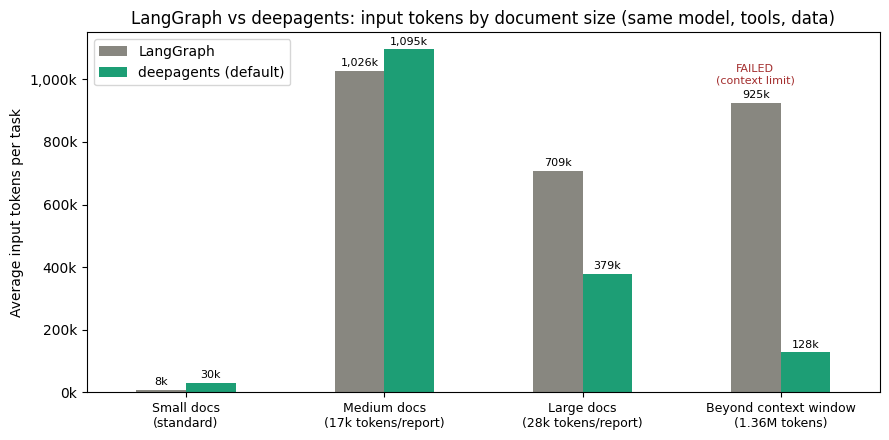

In [ ]:
# Scorecard: combine every run, summarise by scenario and agent, save a CSV and a chart.
import pandas as pd
import matplotlib.pyplot as plt

USD_TO_INR = 93.91
PRICE_IN, PRICE_OUT = 0.75, 3.75          # USD per million tokens (Gemini 3.8 Flash)

all_runs = pd.concat([pd.read_csv("results.csv"),            # standard round
                      pd.read_csv("results_earlier.csv"),    # first stress / scale runs
                      pd.read_csv("results_more.csv")],      # replication runs
                     ignore_index=True)
all_runs["cost_inr"] = (all_runs["input_tokens"] * PRICE_IN + all_runs["output_tokens"] * PRICE_OUT) / 1e6 * USD_TO_INR
all_runs.to_csv("results_all.csv", index=False)

SCENARIO = {"standard": "1. Small docs (standard)",
            "stress_v1": "2. Medium docs (17k tokens/report)",
            "stress_v2": "3. Large docs (28k tokens/report)",
            "scale": "4. Beyond context window (1.36M tokens)"}
all_runs["scenario"] = all_runs["tier"].map(SCENARIO)

scorecard = (all_runs.groupby(["scenario", "agent"])
             .agg(runs=("task", "count"),
                  correct=("correct", "sum"),
                  avg_input_tokens=("input_tokens", "mean"),
                  avg_cost_inr=("cost_inr", "mean"),
                  avg_seconds=("seconds", "mean"),
                  failures=("error", lambda s: s.notna().sum()))
             .reset_index())
scorecard["accuracy"] = scorecard["correct"].astype(int).astype(str) + "/" + scorecard["runs"].astype(str)
scorecard = scorecard[["scenario", "agent", "runs", "accuracy", "avg_input_tokens",
                       "avg_cost_inr", "avg_seconds", "failures"]].round(
                       {"avg_input_tokens": 0, "avg_cost_inr": 1, "avg_seconds": 1})
scorecard.to_csv("scorecard.csv", index=False)
print(scorecard.to_string(index=False))

# Chart: average input tokens per scenario, LangGraph vs deepagents (default)
plot = scorecard[scorecard["agent"].isin(["langgraph", "deepagents"])]
pivot = plot.pivot(index="scenario", columns="agent", values="avg_input_tokens")[["langgraph", "deepagents"]]
ax = pivot.plot(kind="bar", figsize=(9, 4.5), color=["#888780", "#1D9E75"], rot=0)
ax.set_ylabel("Average input tokens per task")
ax.set_xlabel("")
ax.set_title("LangGraph vs deepagents: input tokens by document size (same model, tools, data)")
ax.set_xticklabels([s.split(". ", 1)[1].replace(" (", "\n(") for s in pivot.index], fontsize=9)
failed = plot[(plot["agent"] == "langgraph") & (plot["failures"] > 0)]["scenario"]
for i, s in enumerate(pivot.index):
    if s in set(failed):
        ax.annotate("FAILED\n(context limit)", (i - 0.13, pivot.loc[s, "langgraph"] * 1.06),
                    ha="center", va="bottom", fontsize=8, color="#A32D2D")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v/1000:,.0f}k" for v in c.datavalues], fontsize=8, padding=2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.legend(["LangGraph", "deepagents (default)"])
plt.tight_layout()
plt.savefig("scorecard_tokens.png", dpi=150)
plt.show()

## 12. Follow-up: LangGraph with chunked reading
The beyond-window failure came from whole reports accumulating in LangGraph's message history. Here both agents get the same chunk tools (keyword search + read a 200-line chunk) and no whole-report tool.

Run in a fresh session after sections 1–4, 6 and 9.

In [ ]:
import json
questions = json.load(open("answer_key.json"))   # loaded here instead of the T1 smoke test
print(list(questions.keys()))

['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8']


**Chunk tools**

In [ ]:
@tool
def search_report(name: str, keyword: str) -> str:
    """Search ONE report for a keyword (case-insensitive). Returns the matching lines
    with their line numbers (at most 20). Use it to find where a product or topic
    appears, then read that part with read_report_lines."""
    if not name.endswith(".txt"):
        name = name + ".txt"
    path = os.path.join(REPORT_DIR, name)
    if not os.path.exists(path):
        return f"Error: report '{name}' not found. Available: {sorted(os.listdir(REPORT_DIR))}"
    with open(path) as f:
        lines = f.read().split("\n")
    hits = [f"{i}: {line[:200]}" for i, line in enumerate(lines) if keyword.lower() in line.lower()]
    if not hits:
        return f"No lines contain '{keyword}'. The report has {len(lines)} lines."
    more = f"\n... and {len(hits) - 20} more matches" if len(hits) > 20 else ""
    return "\n".join(hits[:20]) + more

@tool
def read_report_lines(name: str, start: int, n_lines: int = 50) -> str:
    """Read one CHUNK of a report: `n_lines` lines (maximum 200) starting at line
    number `start` (0 = first line). Use it after search_report to read the section
    around a match, or to read a short file such as README_methodology."""
    if not name.endswith(".txt"):
        name = name + ".txt"
    path = os.path.join(REPORT_DIR, name)
    if not os.path.exists(path):
        return f"Error: report '{name}' not found. Available: {sorted(os.listdir(REPORT_DIR))}"
    with open(path) as f:
        lines = f.read().split("\n")
    n_lines = min(n_lines, 200)
    chunk = lines[start:start + n_lines]
    body = "\n".join(f"{start + i}: {line}" for i, line in enumerate(chunk))
    return f"Lines {start}-{start + len(chunk) - 1} of {len(lines)}:\n{body}"

# quick test (no API call)
REPORT_DIR = "reports_scale"
print(search_report.invoke({"name": "austria", "keyword": "xelora"}))
print(read_report_lines.invoke({"name": "austria", "start": 0, "n_lines": 5}))

4223: SECTION C: XELORA (THE PRODUCT IN SCOPE)
4224: Product: Xelora 50 mg, pack of 30 tablets (fictional product, synthetic data)
Lines 0-4 of 8471:
0: COUNTRY PRICING REPORT: AUSTRIA
1: Currency for all prices in this report: EUR
2: 
3: SECTION A: OTHER PRODUCTS AND NOTES
4: Tender T-939 for Norplex closed with 6 bidders; the net price is confidential.


**LangGraph agent with the chunk tools**

In [ ]:
def build_lg_agent(agent_tools):
    llm_t = llm.bind_tools(agent_tools)

    def node(state):
        messages = [SystemMessage(SYSTEM_PROMPT)] + state["messages"]
        return {"messages": [llm_t.invoke(messages)]}

    g = StateGraph(MessagesState)
    g.add_node("agent_node", node)
    g.add_node("tools", ToolNode(agent_tools))
    g.add_edge(START, "agent_node")
    g.add_conditional_edges("agent_node", should_continue, ["tools", END])
    g.add_edge("tools", "agent_node")
    return g.compile()

# read_report (whole file) is NOT given, so the agent must read in chunks
chunk_tools = [list_reports, search_report, read_report_lines]
lg_chunk_agent = build_lg_agent(chunk_tools)

**Runs: LangGraph + chunking** (scale test ×2, large docs T8 ×1)

In [ ]:
import pandas as pd

chunk_runs = [
    ("scale",     "reports_scale",   "S1"),
    ("scale",     "reports_scale",   "S1"),
    ("stress_v2", "reports_long_v2", "T8"),
]
chunk_rows = []
for tier, folder, t in chunk_runs:
    REPORT_DIR = folder
    row = run_and_measure(lg_chunk_agent, "langgraph+chunking", t, tier)
    row["correct"] = grade_scale(row["final"]) if t == "S1" else grade(t, row["final"])
    chunk_rows.append(row)
    pd.DataFrame(chunk_rows).to_csv("results_chunking.csv", index=False)   # save after every run
    print(f"{tier:9} {t} correct={row['correct']} in={row['input_tokens']:,} out={row['output_tokens']:,} "
          f"{row['seconds']}s tools={row['tool_names']} err={row['error']}")

scale     S1 correct=True in=72,975 out=4,781 71.3s tools={'list_reports': 1, 'read_report_lines': 11, 'search_report': 10} err=None
scale     S1 correct=True in=107,927 out=4,858 74.0s tools={'list_reports': 1, 'read_report_lines': 11, 'search_report': 10} err=None
stress_v2 T8 correct=True in=313,812 out=21,449 186.0s tools={'list_reports': 1, 'read_report_lines': 10, 'search_report': 5} err=None


**Runs: deepagents + the same chunk tools** (fair comparison)

In [ ]:
from deepagents import create_deep_agent
from langchain.agents.middleware import TodoListMiddleware

da_chunk_agent = create_deep_agent(
    model=llm,
    tools=chunk_tools,                     # the SAME 3 tools as lg_chunk_agent
    system_prompt=SYSTEM_PROMPT,
    middleware=[TodoListMiddleware()],
)

for tier, folder, t in chunk_runs:         # same 3 runs: scale x2, large T8 x1
    REPORT_DIR = folder
    row = run_and_measure(da_chunk_agent, "deepagents+chunking", t, tier)
    row["correct"] = grade_scale(row["final"]) if t == "S1" else grade(t, row["final"])
    chunk_rows.append(row)
    pd.DataFrame(chunk_rows).to_csv("results_chunking.csv", index=False)
    print(f"{tier:9} {t} correct={row['correct']} in={row['input_tokens']:,} out={row['output_tokens']:,} "
          f"{row['seconds']}s tools={row['tool_names']} err={row['error']}")

scale     S1 correct=True in=71,069 out=5,125 54.6s tools={'list_reports': 1, 'read_report_lines': 11, 'write_todos': 3, 'search_report': 10} err=None
scale     S1 correct=True in=58,928 out=4,387 42.9s tools={'list_reports': 1, 'read_report_lines': 12, 'search_report': 10} err=None
stress_v2 T8 correct=True in=440,357 out=23,737 181.2s tools={'list_reports': 1, 'read_report_lines': 13, 'write_todos': 3, 'search_report': 8} err=None


**Summary**

In [ ]:
USD_TO_INR, PRICE_IN, PRICE_OUT = 93.91, 0.75, 3.75
ch = pd.DataFrame(chunk_rows)
ch["cost_inr"] = (ch["input_tokens"] * PRICE_IN + ch["output_tokens"] * PRICE_OUT) / 1e6 * USD_TO_INR

# every run
print(ch[["agent", "tier", "task", "correct", "input_tokens", "output_tokens", "cost_inr", "seconds"]].round(1))

# summary: one row per agent and tier
summary = (ch.groupby(["tier", "agent"])
             .agg(runs=("task", "count"), correct=("correct", "sum"),
                  avg_input_tokens=("input_tokens", "mean"), avg_cost_inr=("cost_inr", "mean"),
                  avg_seconds=("seconds", "mean"))
             .round(1).reset_index())
print("\n", summary)
summary.to_csv("chunking_summary.csv", index=False)

print("\nEarlier (README): scale  -> LangGraph failed at 924,796 input tokens; deepagents 3/3 at ~127,539")
print("                  large  -> LangGraph ~708,697; deepagents ~378,897 input tokens")

                 agent       tier task  correct  input_tokens  output_tokens  \
0   langgraph+chunking      scale   S1     True         72975           4781   
1   langgraph+chunking      scale   S1     True        107927           4858   
2   langgraph+chunking  stress_v2   T8     True        313812          21449   
3  deepagents+chunking      scale   S1     True         71069           5125   
4  deepagents+chunking      scale   S1     True         58928           4387   
5  deepagents+chunking  stress_v2   T8     True        440357          23737   

   cost_inr  seconds  
0       6.8     71.3  
1       9.3     74.0  
2      29.7    186.0  
3       6.8     54.6  
4       5.7     42.9  
5      39.4    181.2  

         tier                agent  runs  correct  avg_input_tokens  \
0      scale  deepagents+chunking     2        2           64998.5   
1      scale   langgraph+chunking     2        2           90451.0   
2  stress_v2  deepagents+chunking     1        1          440357.0

**Findings**
- With chunk tools, LangGraph passes the beyond-window test (2/2, ~90k input tokens) that it failed with whole-report reading.
- With the same tools, both agents were correct on every run: scale ~90k (LangGraph) vs ~65k (deepagents) input tokens, large docs 314k vs 440k. Differences are within run-to-run variance (1–2 runs each).
- So the deciding factor is context management, not the framework: deepagents provides it out of the box for large tool outputs; in LangGraph it needed data-specific chunk tools.